# Лабораторная работа №1. Изображение как матрица: статистика, ковариация и расстояния

Условие — в [методичке](CSE5382_15_лабораторных_работ_математические_методы_in_CV.md), раздел «Лабораторная работа №1».
Ноутбук идёт от простого к сложному: сначала идея на бытовом примере, потом понятия и формулы,
потом два ручных расчёта с проверкой в NumPy и программная часть.

**Данные.** `data/building.jpg` (868×600) — стандартный пример из набора OpenCV. Для сдачи его можно заменить своей фотографией: код от картинки не зависит.

## 1. О чём эта работа

### Знакомый пример

Откройте фотографию в графическом редакторе и увеличивайте, пока не увидите квадратики. Каждый квадратик — **пиксель**, и у него три числа: сколько в нём красного, зелёного и синего (от 0 до 255). Фотография для компьютера — это просто большая таблица таких чисел.

### Основная идея

Раз картинка — таблица чисел, к ней применима обычная статистика: «какая картинка в среднем яркая», «насколько сильно яркость скачет», «меняются ли красный и зелёный вместе». Эти числа — первое, что нужно знать о данных, прежде чем применять любой алгоритм.

### Понятия, которые понадобятся

- **Матрица** — прямоугольная таблица чисел. Серое изображение — матрица `H×W` (высота × ширина).
- **Тензор** — таблица с бо́льшим числом измерений. Цветное изображение — `H×W×3`: три матрицы (каналы R, G, B), сложенные стопкой.
- **Среднее** $\mu$ — «типичное» значение: сумма всех чисел, делённая на их количество.
- **Дисперсия** $\sigma^2$ — средний квадрат отклонения от среднего. Маленькая дисперсия — все числа рядом со средним (ровный серый фон), большая — числа разбросаны (контрастная картинка). Корень из неё, $\sigma$, называется **стандартным отклонением** и измеряется в тех же единицах, что и яркость.
- **Ковариация** двух величин показывает, меняются ли они вместе. Положительная — когда одна больше своего среднего, другая обычно тоже; отрицательная — наоборот; около нуля — не связаны.
- **Норма** — «длина» объекта одним числом. Норма Фробениуса считает матрицу длинным вектором и берёт его обычную длину.
- **Расстояние** между пикселем и средним цветом говорит, насколько пиксель «необычный».

### Формулы

$$\mu=\frac1N\sum_{i=1}^{N}x_i,\qquad \sigma^2=\frac1N\sum_{i=1}^{N}(x_i-\mu)^2$$

Здесь $x_i$ — значения пикселей, $N$ — их количество.

$$\mathrm{Cov}(X,Y)=\frac1N\sum_{i}(x_i-\mu_x)(y_i-\mu_y)$$

$x_i, y_i$ — значения двух каналов в одном и том же пикселе. Если собрать ковариации всех пар каналов в таблицу, получится **ковариационная матрица** $\Sigma$ размера 3×3: на диагонали дисперсии каналов, вне диагонали — ковариации пар.

$$\|A\|_F=\sqrt{\sum_i\sum_j a_{ij}^2}$$

**Евклидово расстояние** — обычная длина разности: $d_E=\sqrt{(x-\mu)^T(x-\mu)}$.

**Расстояние Махаланобиса** делает то же, но сначала «выравнивает масштабы»:

$$d_M(x,\mu)=\sqrt{(x-\mu)^T\,\Sigma^{-1}\,(x-\mu)}$$

Умножение на $\Sigma^{-1}$ делит каждое отклонение на типичный разброс в этом направлении. Отклонение на 10 единиц там, где канал почти не меняется, — событие; там, где канал гуляет на сотни, — пустяк. Если $\Sigma$ — единичная матрица, $d_M$ превращается в $d_E$.

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.dpi": 80, "image.cmap": "gray"})

IMAGE_PATH = "data/building.jpg"
SEED = 0
rng = np.random.default_rng(SEED)

## 2. Вопрос 1 — среднее, дисперсия и норма Фробениуса

> Для `I=[[12,18,24],[30,36,42],[48,54,60]]` найдите μ, σ² и Frobenius-норму.

**Шаг 1. Среднее.** Складываем девять чисел: $12+18+24+30+36+42+48+54+60=324$. Делим на количество: $\mu=324/9=36$.

Быстрая проверка без калькулятора: числа идут с шагом 6, это арифметическая прогрессия, её среднее — центральный элемент, то есть 36.

**Шаг 2. Отклонения от среднего.** Из каждого числа вычитаем 36: $-24,-18,-12,-6,0,6,12,18,24$. Их сумма всегда ноль — так устроено среднее.

**Шаг 3. Дисперсия.** Возводим отклонения в квадрат: $576,324,144,36,0,36,144,324,576$. Сумма $=2160$. Делим на 9: $\sigma^2=240$, значит $\sigma=\sqrt{240}\approx15.49$.

**Шаг 4. Норма Фробениуса.** Теперь в квадрат возводим сами элементы (без вычитания среднего): $144+324+576+900+1296+1764+2304+2916+3600=13824$. Корень: $\|I\|_F=\sqrt{13824}\approx117.58$.

**Связь между ними.** Сумма квадратов элементов $=N(\sigma^2+\mu^2)=9\cdot(240+1296)=13824$. То есть норма Фробениуса смешивает «общий уровень» ($\mu$) и «разброс» ($\sigma$); дисперсия оставляет только разброс.

In [ ]:
I = np.array([[12, 18, 24], [30, 36, 42], [48, 54, 60]], dtype=float)

mu = I.sum() / I.size
dev = I - mu
var = (dev ** 2).sum() / I.size
fro = np.sqrt((I ** 2).sum())

print("сумма элементов      :", I.sum())
print("μ                    :", mu)
print("отклонения           :", dev.ravel())
print("сумма квадратов откл.:", (dev ** 2).sum())
print("σ²                   :", var, "  σ =", round(np.sqrt(var), 4))
print("сумма квадратов эл.  :", (I ** 2).sum())
print("||I||_F              :", round(fro, 4))

# проверка библиотекой и тождество N(σ²+μ²)
assert np.isclose(mu, I.mean()) and np.isclose(var, I.var()) and np.isclose(fro, np.linalg.norm(I, "fro"))
print("N(σ²+μ²)             :", I.size * (var + mu ** 2))

сумма элементов      : 324.0
μ                    : 36.0
отклонения           : [-24. -18. -12.  -6.   0.   6.  12.  18.  24.]
сумма квадратов откл.: 2160.0
σ²                   : 240.0   σ = 15.4919
сумма квадратов эл.  : 13824.0
||I||_F              : 117.5755
N(σ²+μ²)             : 13824.0


**Итог вопроса 1:** $\mu=36$, $\sigma^2=240$, $\|I\|_F\approx117.58$ — совпадает с NumPy.

## 3. Вопрос 2 — расстояние Махаланобиса

> Для μ=(100,120,80), x=(120,130,90), Σ=diag(400,100,25) вычислите Mahalanobis distance.

**Что дано простыми словами.** Средний цвет — (100, 120, 80). Матрица $\Sigma$ диагональная, значит каналы между собой не связаны, а на диагонали стоят их дисперсии: 400, 100 и 25. Стандартные отклонения — корни: $\sigma_R=20$, $\sigma_G=10$, $\sigma_B=5$. Красный «гуляет» сильно, синий почти не меняется.

**Шаг 1. Отклонение.** $x-\mu=(20,10,10)$.

**Шаг 2. Обратная матрица.** У диагональной матрицы обратная получается переворотом диагонали: $\Sigma^{-1}=\mathrm{diag}(1/400,\,1/100,\,1/25)$.

**Шаг 3. Квадрат расстояния.** Для диагональной $\Sigma$ формула превращается в сумму «отклонение в квадрате, делённое на дисперсию»:

$$d_M^2=\frac{20^2}{400}+\frac{10^2}{100}+\frac{10^2}{25}=1+1+4=6$$

**Шаг 4. Расстояние.** $d_M=\sqrt6\approx2.449$.

**Смысл.** Каждое слагаемое — квадрат отклонения, измеренного в «сигмах» своего канала: R ушёл на $20/20=1\sigma$, G на $10/10=1\sigma$, B на $10/5=2\sigma$. Отклонения G и B одинаковы по абсолютной величине (по 10 единиц), но для синего это вдвое более редкое событие, и в $d_M^2$ оно даёт 4 против 1. Евклидово расстояние этого не видит: $d_E=\sqrt{400+100+100}\approx24.49$, и главным в нём оказывается красный канал — самый шумный и потому наименее информативный.

In [ ]:
mu_v = np.array([100.0, 120.0, 80.0])
x_v = np.array([120.0, 130.0, 90.0])
Sigma_d = np.diag([400.0, 100.0, 25.0])

d = x_v - mu_v
terms = d ** 2 / np.diag(Sigma_d)
d_m = np.sqrt(d @ np.linalg.inv(Sigma_d) @ d)

print("x − μ                :", d)
print("отклонения в сигмах  :", d / np.sqrt(np.diag(Sigma_d)))
print("слагаемые d²         :", terms, " сумма =", terms.sum())
print("Mahalanobis          :", round(d_m, 4))
print("Euclidean            :", round(np.linalg.norm(d), 4))
print("вклад каналов в d_E² :", d ** 2 / (d ** 2).sum())
print("вклад каналов в d_M² :", terms / terms.sum())

x − μ                : [20. 10. 10.]
отклонения в сигмах  : [1. 1. 2.]
слагаемые d²         : [1. 1. 4.]  сумма = 6.0
Mahalanobis          : 2.4495
Euclidean            : 24.4949
вклад каналов в d_E² : [0.6667 0.1667 0.1667]
вклад каналов в d_M² : [0.1667 0.1667 0.6667]


**Итог вопроса 2:** $d_M=\sqrt6\approx2.449$. В евклидовом расстоянии 2/3 вклада даёт красный канал, в расстоянии Махаланобиса 2/3 вклада даёт синий — тот, где отклонение статистически значимее.

## 4. Задание 3 — код и эксперимент

Шаги пронумерованы так же, как в методичке.

### Шаги 1–3. Загрузка, свойства, BGR→RGB

OpenCV исторически хранит каналы в порядке **B, G, R**. Matplotlib ждёт R, G, B, поэтому для показа и для подписей каналов массив переворачиваем. На статистику порядок не влияет — меняется только то, какой столбец как называется.

shape : (600, 868, 3) (высота, ширина, каналы)
dtype : uint8
min   : 0  max: 255
nbytes: 1562400 = 600 × 868 × 3 × 1 байт = 1562400
в float64 тот же массив занял бы 12499200 байт (в 8 раз больше)


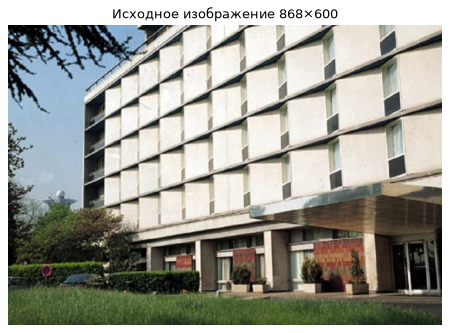

In [ ]:
img_bgr = cv2.imread(IMAGE_PATH)
assert img_bgr is not None, IMAGE_PATH
img_u8 = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
H, W, C = img_u8.shape

print("shape :", img_u8.shape, "(высота, ширина, каналы)")
print("dtype :", img_u8.dtype)
print("min   :", img_u8.min(), " max:", img_u8.max())
print("nbytes:", img_u8.nbytes, "=", H, "×", W, "×", C, "× 1 байт =", H * W * C)
print("в float64 тот же массив занял бы", H * W * C * 8, "байт (в 8 раз больше)")

plt.figure(figsize=(7, 5))
plt.imshow(img_u8)
plt.title(f"Исходное изображение {W}×{H}")
plt.axis("off")
plt.show()

**Откуда объём памяти.** Тип `uint8` — целое от 0 до 255, занимает ровно 1 байт. Чисел в массиве `H·W·C`, поэтому `nbytes = H·W·C`. Файл на диске меньше, потому что JPEG сжат; в памяти картинка лежит распакованной.

Для вычислений переводим в `float64`: в `uint8` разность `10 − 20` дала бы 246 (переполнение), а квадраты не поместились бы в байт.

### Шаги 4–5. Развёртка в N×3 и статистика каналов

`reshape(-1, 3)` вытягивает картинку в длинный список пикселей: строка — один пиксель, столбцы — R, G, B. Соседство пикселей теряется, но для статистики оно и не нужно.

X.shape = (520800, 3)  N = H·W = 520800

канал       mean    variance      std   median
R        142.925    6893.236   83.026    149.0
G        143.583    6536.729   80.850    151.0
B        133.721    7214.520   84.938    140.0


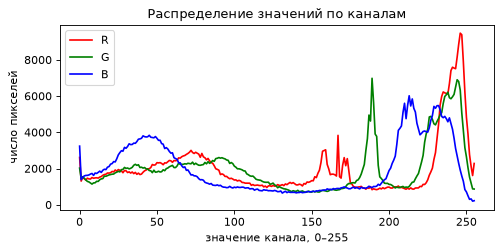

In [ ]:
img = img_u8.astype(np.float64)
X = img.reshape(-1, 3)
N = len(X)
print("X.shape =", X.shape, " N = H·W =", H * W)

mu = X.sum(axis=0) / N
var = ((X - mu) ** 2).sum(axis=0) / N
std = np.sqrt(var)
med = np.median(X, axis=0)

print(f"\n{'канал':6}{'mean':>10}{'variance':>12}{'std':>9}{'median':>9}")
for k, name in enumerate("RGB"):
    print(f"{name:6}{mu[k]:10.3f}{var[k]:12.3f}{std[k]:9.3f}{med[k]:9.1f}")

assert np.allclose(mu, X.mean(axis=0)) and np.allclose(var, X.var(axis=0))

fig, ax = plt.subplots(figsize=(7, 3))
for k, col in enumerate(["red", "green", "blue"]):
    ax.plot(np.bincount(img_u8[..., k].ravel(), minlength=256), color=col, label="RGB"[k])
ax.set(title="Распределение значений по каналам", xlabel="значение канала, 0–255", ylabel="число пикселей")
ax.legend()
plt.show()

### Шаг 6. Ковариационная матрица 3×3 своей формулой

Вычитаем из каждого столбца его среднее — получаем центрированную матрицу $X_c$ размера `N×3`. Тогда

$$\Sigma=\frac1N X_c^{T}X_c$$

Почему это работает: элемент $(a,b)$ произведения $X_c^TX_c$ — это скалярное произведение столбца $a$ на столбец $b$, то есть $\sum_i (x_{ia}-\mu_a)(x_{ib}-\mu_b)$ — ровно числитель ковариации. Одно матричное умножение считает сразу все девять пар.

`np.cov` по умолчанию делит на $N-1$ (несмещённая оценка), а формула методички — на $N$. Чтобы сравнение было честным, передаём `bias=True`.

Ковариация зависит от масштаба, поэтому рядом считаем **корреляцию** $\rho_{ab}=\Sigma_{ab}/(\sigma_a\sigma_b)$ — ту же связь, но приведённую к диапазону от −1 до 1.

In [ ]:
Xc = X - mu
Sigma = (Xc.T @ Xc) / N
Sigma_np = np.cov(X, rowvar=False, bias=True)
corr = Sigma / np.outer(std, std)

print("Σ (своя формула):\n", Sigma)
print("max |Σ − np.cov| =", np.abs(Sigma - Sigma_np).max())
print("симметрична:", np.allclose(Sigma, Sigma.T))
print("диагональ совпадает с дисперсиями:", np.allclose(np.diag(Sigma), var))
print("\nкорреляция каналов:\n", corr)

Σ (своя формула):
 [[6893.2355 6614.4584 6767.2035]
 [6614.4584 6536.7287 6739.7716]
 [6767.2035 6739.7716 7214.5196]]
max |Σ − np.cov| = 0.0
симметрична: True
диагональ совпадает с дисперсиями: True

корреляция каналов:
 [[1.     0.9854 0.9596]
 [0.9854 1.     0.9814]
 [0.9596 0.9814 1.    ]]


### Шаги 7–8. Евклидово и махаланобисово расстояние для 10 пикселей

Берём 10 случайных пикселей (seed зафиксирован) и для каждого считаем оба расстояния до среднего цвета. `np.linalg.pinv` — псевдообратная матрица: если какой-то канал почти линейно выражается через другие, обычная обратная «взрывается», а псевдообратная остаётся конечной.

In [ ]:
Sigma_inv = np.linalg.pinv(Sigma)
idx = rng.choice(N, size=10, replace=False)
P = X[idx]
D = P - mu

d_euc = np.sqrt((D ** 2).sum(axis=1))
d_mah = np.sqrt(np.einsum("ni,ij,nj->n", D, Sigma_inv, D))

print(f"{'#':>2} {'(row,col)':>11} {'R':>5}{'G':>5}{'B':>5} {'Euclid':>9} {'Mahal':>8} {'ранг E':>7}{'ранг M':>7}")
rank_e = d_euc.argsort().argsort() + 1
rank_m = d_mah.argsort().argsort() + 1
for n, i in enumerate(idx):
    r, c = divmod(i, W)
    print(f"{n:2d} {f'({r},{c})':>11} {P[n,0]:5.0f}{P[n,1]:5.0f}{P[n,2]:5.0f} {d_euc[n]:9.2f} {d_mah[n]:8.3f} {rank_e[n]:7d}{rank_m[n]:7d}")

# по всем пикселям: насколько согласованы два расстояния
D_all = X - mu
e_all = np.sqrt((D_all ** 2).sum(axis=1))
m_all = np.sqrt(np.einsum("ni,ij,nj->n", D_all, Sigma_inv, D_all))
print("\nкорреляция Euclid и Mahalanobis по всем пикселям:", round(np.corrcoef(e_all, m_all)[0, 1], 3))
print("средний d_M² по всем пикселям:", round((m_all ** 2).mean(), 3), "(теоретически равен числу каналов, 3)")

 #   (row,col)     R    G    B    Euclid    Mahal  ранг E ранг M
 0   (510,317)     9   16    9    223.09    1.652      10      8
 1   (487,835)    63   62   57    137.59    1.146       5      2
 2   (382,148)    94   81   62    107.02    1.297       3      7
 3   (306,588)   248  245  240    180.61    1.275       9      5
 4   (161,755)    73   69   68    121.54    1.281       4      6
 5    (24,506)   244  243  238    176.00    1.236       8      4
 6     (9,795)   236  232  221    155.24    1.138       6      1
 7   (184,604)   238  235  228    162.13    1.146       7      3
 8   (105,139)   155  186  214     91.60    2.871       2     10
 9    (45,124)   154  179  209     83.93    2.718       1      9



корреляция Euclid и Mahalanobis по всем пикселям: 0.055
средний d_M² по всем пикселям: 3.0 (теоретически равен числу каналов, 3)


Столбцы «ранг» показывают место пикселя по удалённости (1 — самый близкий к среднему). Если ранги по двум расстояниям различаются, значит, расстояния по-разному отвечают на вопрос «какой пиксель необычнее».

Средний $d_M^2$ по всем пикселям равен числу каналов — это свойство формулы, удобная проверка, что $\Sigma^{-1}$ посчитана правильно.

### Шаги 9–10. RGB→Gray как матричное умножение и сравнение с OpenCV

Серое значение — взвешенная сумма каналов: $Y=0.299R+0.587G+0.114B$. Веса разные, потому что глаз чувствительнее всего к зелёному и слабее всего к синему. В матричном виде: матрица пикселей `N×3`, умноженная на вектор весов длины 3, даёт вектор длины N.

сумма весов          : 0.9999999999999999
MAE (float − OpenCV) : 0.1708
max |Δ|              : 0.499
после округления: MAE = 0.0  max = 0.0


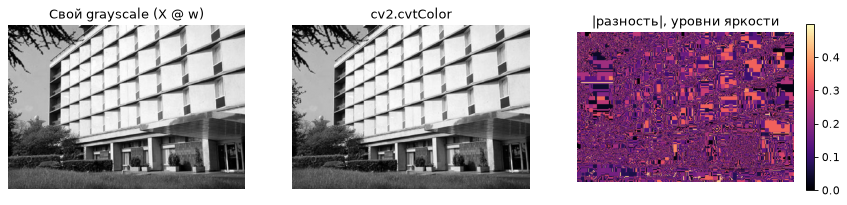

In [ ]:
w = np.array([0.299, 0.587, 0.114])
gray_manual = (X @ w).reshape(H, W)
gray_cv = cv2.cvtColor(img_u8, cv2.COLOR_RGB2GRAY).astype(np.float64)

diff = np.abs(gray_manual - gray_cv)
diff_rounded = np.abs(np.rint(gray_manual) - gray_cv)
print("сумма весов          :", w.sum())
print("MAE (float − OpenCV) :", round(diff.mean(), 4))
print("max |Δ|              :", round(diff.max(), 4))
print("после округления: MAE =", round(diff_rounded.mean(), 5), " max =", diff_rounded.max())

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].imshow(gray_manual, vmin=0, vmax=255); ax[0].set_title("Свой grayscale (X @ w)")
ax[1].imshow(gray_cv, vmin=0, vmax=255); ax[1].set_title("cv2.cvtColor")
im = ax[2].imshow(diff, cmap="magma"); ax[2].set_title("|разность|, уровни яркости")
plt.colorbar(im, ax=ax[2], fraction=0.035)
for a in ax: a.axis("off")
plt.show()

Разность меньше одного уровня яркости: наш результат дробный, а OpenCV округляет до целого и считает в целочисленной арифметике с фиксированной точкой. После округления результаты почти совпадают.

## 5. Неудачный случай: когда Махаланобис ломается

Возьмём маленький участок 40×40 в левой верхней части кадра (небо и ветки). Внутри него цвет меняется почти только по яркости, каналы почти точно повторяют друг друга, поэтому $\Sigma$ становится почти вырожденной: одно из её собственных значений близко к нулю. Обратная матрица делит на это почти-нулевое число, и расстояние начинает усиливать шум в тысячи раз.

In [ ]:
patch = img[90:130, 100:140].reshape(-1, 3)        # участок чистого неба
mu_p = patch.mean(axis=0)
Sig_p = np.cov(patch, rowvar=False, bias=True)
eig = np.linalg.eigvalsh(Sig_p)
print("std каналов в патче :", patch.std(axis=0))
print("собственные значения Σ:", eig)
print("число обусловленности :", round(eig[-1] / max(eig[0], 1e-12), 1))

# один и тот же сдвиг на 3 уровня яркости, но в разных направлениях цветового пространства
vals, vecs = np.linalg.eigh(Sig_p)
for name, direction in [("вдоль главной оси разброса", vecs[:, -1]), ("вдоль самой «тонкой» оси", vecs[:, 0])]:
    x_test = mu_p + 3 * direction
    dm = np.sqrt((x_test - mu_p) @ np.linalg.pinv(Sig_p) @ (x_test - mu_p))
    print(f"сдвиг на 3 уровня {name:28}: Euclid = 3.00, Mahalanobis = {dm:.2f}")

std каналов в патче : [28.9928 32.3438 35.5017]
собственные значения Σ: [   1.4212    9.7861 3135.8641]
число обусловленности : 2206.5
сдвиг на 3 уровня вдоль главной оси разброса  : Euclid = 3.00, Mahalanobis = 0.05
сдвиг на 3 уровня вдоль самой «тонкой» оси    : Euclid = 3.00, Mahalanobis = 2.52


Один и тот же сдвиг на 3 уровня яркости даёт махаланобисово расстояние, отличающееся в разы, — в зависимости от направления. Вдоль «тонкой» оси разброса почти нет, поэтому любое отклонение (в том числе шум JPEG и округления) объявляется сильной аномалией. Вывод: расстояние Махаланобиса надёжно, только когда $\Sigma$ оценена по достаточно разнообразным данным; на однородных областях нужна регуляризация ($\Sigma+\varepsilon I$) или `pinv` с отсечением малых собственных значений.

Второе ограничение: формула предполагает одно «облако» вокруг одного среднего. У нашей картинки облаков несколько (небо, здание, трава), и средний цвет не соответствует ни одному из них.

## 6. Вывод

Цифры ниже относятся к `data/building.jpg`; при замене изображения вывод нужно переписать по новым таблицам.

- Изображение 868×600×3 в `uint8` занимает 1 562 400 байт — по байту на число.
- Корреляции каналов (ячейка шага 6): **R–G ≈ 0.985**, **G–B ≈ 0.981**, **R–B ≈ 0.960**. Все положительные и очень высокие: главное различие между пикселями этой картинки — «светлее/темнее», и при изменении яркости все три канала растут вместе. Слабее всего связаны R и B: синее небо поднимает B и опускает R.
- Разброс каналов почти одинаковый (std ≈ 83, 81, 85), средние тоже близки (≈ 143, 144, 134) — в среднем картинка почти серая.
- Евклидово расстояние и расстояние Махаланобиса почти не связаны между собой: корреляция по всем пикселям ≈ 0.06. В таблице шага 7–8 это видно на двух пикселях неба (№ 8 и № 9, цвет около (155, 185, 210)): по евклидову расстоянию они **самые близкие** к среднему цвету (ранги 1 и 2), по Махаланобису — **самые далёкие** (ранги 9 и 10). Причина: небо по яркости среднее, но у него необычное соотношение каналов (B намного больше R), а именно это направление в данных почти не встречается. Тёмный пиксель № 0 — наоборот: евклидово далеко (223), по Махаланобису обычный (1.65), потому что «все каналы одновременно малы» — типичное отклонение вдоль оси яркости.
- Собственный grayscale отличается от `cv2.cvtColor` в среднем на ≈0.17 уровня и не более чем на 0.5; после округления до целых разности нет совсем — формула та же.
- Ограничение: на однородной области $\Sigma$ почти вырождена, и расстояние Махаланобиса усиливает шум (раздел 5).

## 7. Вопросы на защиту

**1. Почему covariance matrix симметрична и что означает знак внедиагонального элемента?**
$\mathrm{Cov}(X,Y)$ — сумма произведений $(x_i-\mu_x)(y_i-\mu_y)$; от перестановки множителей произведение не меняется, поэтому $\Sigma_{ab}=\Sigma_{ba}$. В матричной записи: $(X_c^TX_c)^T=X_c^TX_c$. Знак: плюс — каналы обычно отклоняются от своих средних в одну сторону, минус — в разные, около нуля — линейной связи нет.

**2. В чём отличие Mahalanobis от Euclidean?**
Евклидово расстояние считает все направления равноценными. Махаланобис сначала делит отклонение на типичный разброс данных в этом направлении и учитывает связь между каналами. Геометрически: евклидовы «точки на одном расстоянии» лежат на сфере, махаланобисовы — на эллипсоиде, вытянутом так же, как облако данных. При $\Sigma=I$ расстояния совпадают.

**3. Строка кода с covariance matrix без `np.cov`.**
`Xc = X - mu` — вычитаем из каждого столбца его среднее (broadcasting: вектор длины 3 вычитается из каждой строки). `Xc.T @ Xc` — матрица 3×N умножается на N×3, получается 3×3; элемент $(a,b)$ — скалярное произведение центрированных столбцов $a$ и $b$. Деление на `N` превращает сумму в среднее. Второе матричное умножение в работе — `X @ w`: N×3 на вектор длины 3, результат — N серых значений.